In [9]:
import os
os.environ["CUDA_VISIBLE_DEVICES"] = '4'
os.environ['HDF5_USE_FILE_LOCKING'] = 'FALSE'
import h5py
import torch
import numpy as np
import matplotlib.pyplot as plt
from torch.utils.data import DataLoader
from utils.models import *
from utils.dataloader import *
from utils.utils_sig import *

모델 로드 완료
추론 완료: preds (50, 300), targets (50, 300)


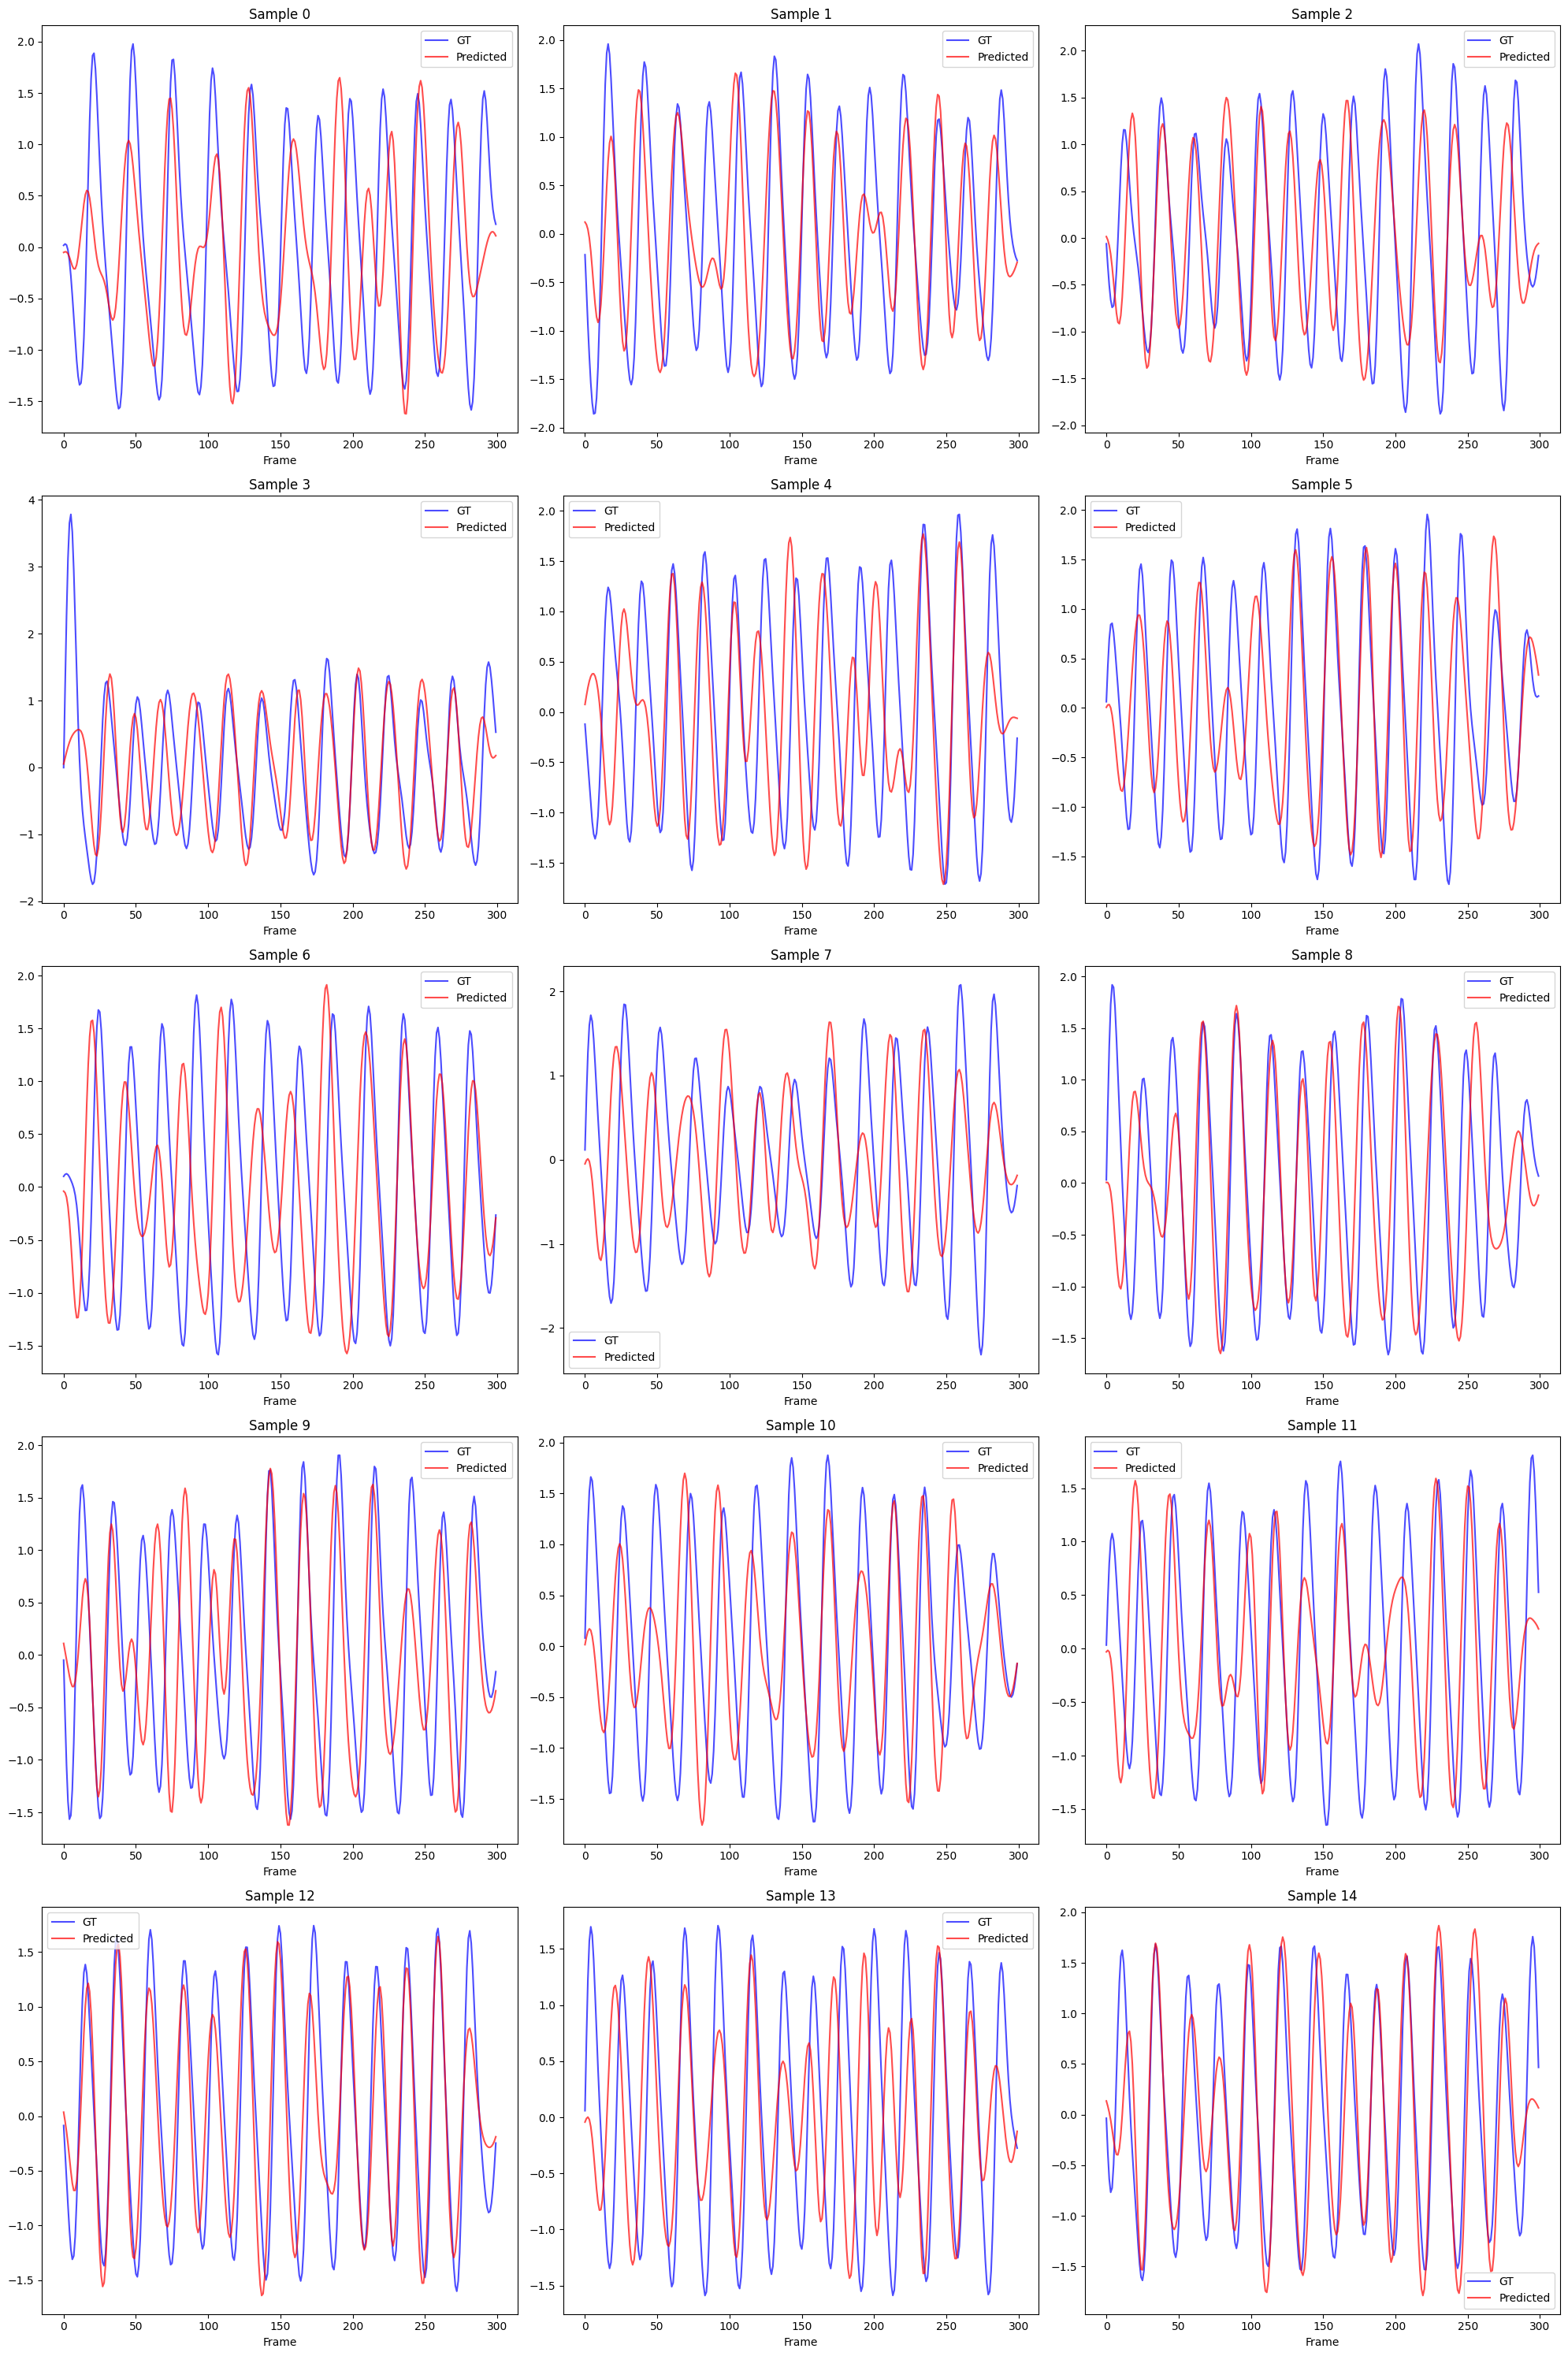

In [16]:
# ===== 설정 =====
device = torch.device("cuda" if torch.cuda.is_available() else "cpu")
pth_path = '/home/son/orientation-uv-rppg/data/codes/deeplearning/parameters_save/mr_nirp_0.0005_8_0.5407.pth'
data_dir = '/nasdata4/2yhy/rPPG_code/rPPG_datasets/raw_data/CNA_members/KM_preprocess_data/MR-nirp_dl_data'
pic_save_dir ='/home/son/orientation-uv-rppg/data/pics'
# ===== 모델 로드 =====
model = PhysNet_padding_Encoder_Decoder_MAX().to(device)
model.load_state_dict(torch.load(pth_path, map_location=device))
model.eval()
print("모델 로드 완료")

# ===== 데이터 로드 =====
all_files = sorted([os.path.join(data_dir, f) for f in os.listdir(data_dir) if f.endswith('.h5')])
valid_files = all_files[:4]  # 학습 때 valid로 썼던 것

valid_dataset = rPPGDataset(valid_files)
valid_loader  = DataLoader(valid_dataset, batch_size=8, shuffle=False, num_workers=4)


# ===== 데이터 로드 =====
all_files = sorted([os.path.join(data_dir, f) for f in os.listdir(data_dir) if f.endswith('.h5')])
valid_files = all_files[:4]  # 학습 때 valid로 썼던 것

valid_dataset = rPPGDataset(valid_files)
valid_loader  = DataLoader(valid_dataset, batch_size=8, shuffle=False, num_workers=4)

# ===== 추론 =====
all_preds   = []
all_targets = []

with torch.no_grad():
    for inputs, targets in valid_loader:
        inputs  = inputs.to(device)
        outputs, _, _, _ = model(inputs)

        all_preds.append(outputs.cpu().numpy())
        all_targets.append(targets.numpy())

all_preds   = np.concatenate(all_preds,   axis=0)  # (N, 300)
all_targets = np.concatenate(all_targets, axis=0)  # (N, 300)

for i in range(len(all_preds)) :
    all_preds[i] = butter_bandpass_filter(all_preds[i], 0.75, 2.5, 30)

print(f"추론 완료: preds {all_preds.shape}, targets {all_targets.shape}")

# ===== Plot =====
n_plot = 15  # 몇 개 샘플 볼지
fig, axes = plt.subplots(5, 3, figsize=(20, 30))
axes = axes.flatten()

for i in range(n_plot):
    axes[i].plot(all_targets[i], label='GT',        color='blue',  alpha=0.7)
    axes[i].plot(all_preds[i],   label='Predicted', color='red',   alpha=0.7)
    axes[i].set_title(f'Sample {i}')
    axes[i].legend()
    axes[i].set_xlabel('Frame')

plt.tight_layout()
plt.savefig(os.path.join(pic_save_dir, 'nirp_uv_valid_timedomain'), dpi= 100)
plt.show()


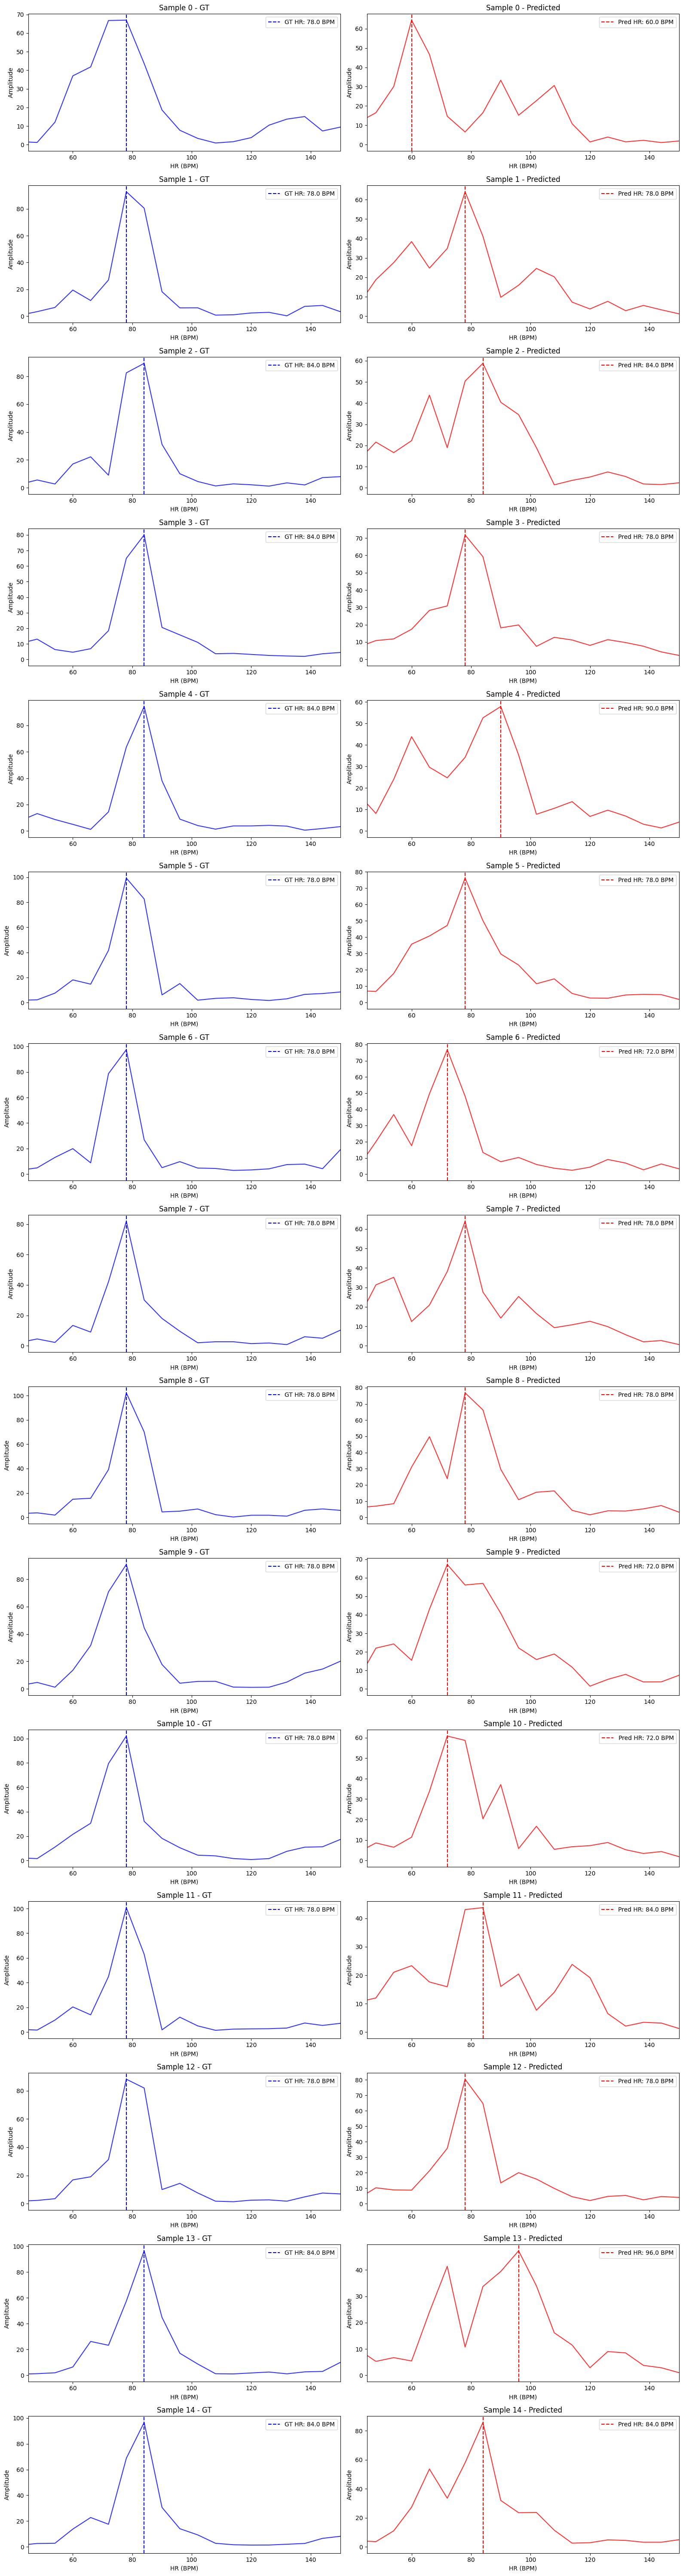

저장완료: fft_comparison.png


<Figure size 640x480 with 0 Axes>

In [17]:
from scipy.fft import fft

n_plot = 15
fig, axes = plt.subplots(n_plot, 2, figsize=(16, 4*n_plot))

for i in range(n_plot):
    pred_sig = all_preds[i]
    gt_sig   = all_targets[i]

    hr_pred, psd_pred, x_hr_pred = hr_fft(pred_sig, fs=30)
    hr_gt,   psd_gt,   x_hr_gt   = hr_fft(gt_sig,   fs=30)

    # GT PSD
    axes[i, 0].plot(x_hr_gt, psd_gt, color='blue', alpha=0.8)
    axes[i, 0].axvline(hr_gt,   color='blue',  linestyle='--', label=f'GT HR: {hr_gt:.1f} BPM')
    axes[i, 0].set_xlim(0.75*60, 2.5*60)
    axes[i, 0].set_title(f'Sample {i} - GT')
    axes[i, 0].set_xlabel('HR (BPM)')
    axes[i, 0].set_ylabel('Amplitude')
    axes[i, 0].legend()

    # Pred PSD
    axes[i, 1].plot(x_hr_pred, psd_pred, color='red', alpha=0.8)
    axes[i, 1].axvline(hr_pred, color='red',   linestyle='--', label=f'Pred HR: {hr_pred:.1f} BPM')
    axes[i, 1].set_xlim(0.75*60, 2.5*60)
    axes[i, 1].set_title(f'Sample {i} - Predicted')
    axes[i, 1].set_xlabel('HR (BPM)')
    axes[i, 1].set_ylabel('Amplitude')
    axes[i, 1].legend()

plt.tight_layout()

plt.show()
plt.savefig(os.path.join(pic_save_dir, 'nirp_uv_valid_frequencydomain'), dpi= 100)
print("저장완료: fft_comparison.png")

# driving data test

모델 로드 완료
torch.Size([8, 1, 300, 64, 64])
torch.Size([8, 1, 300, 64, 64])
torch.Size([3, 1, 300, 64, 64])
추론 완료: preds (19, 300), targets (19, 300)


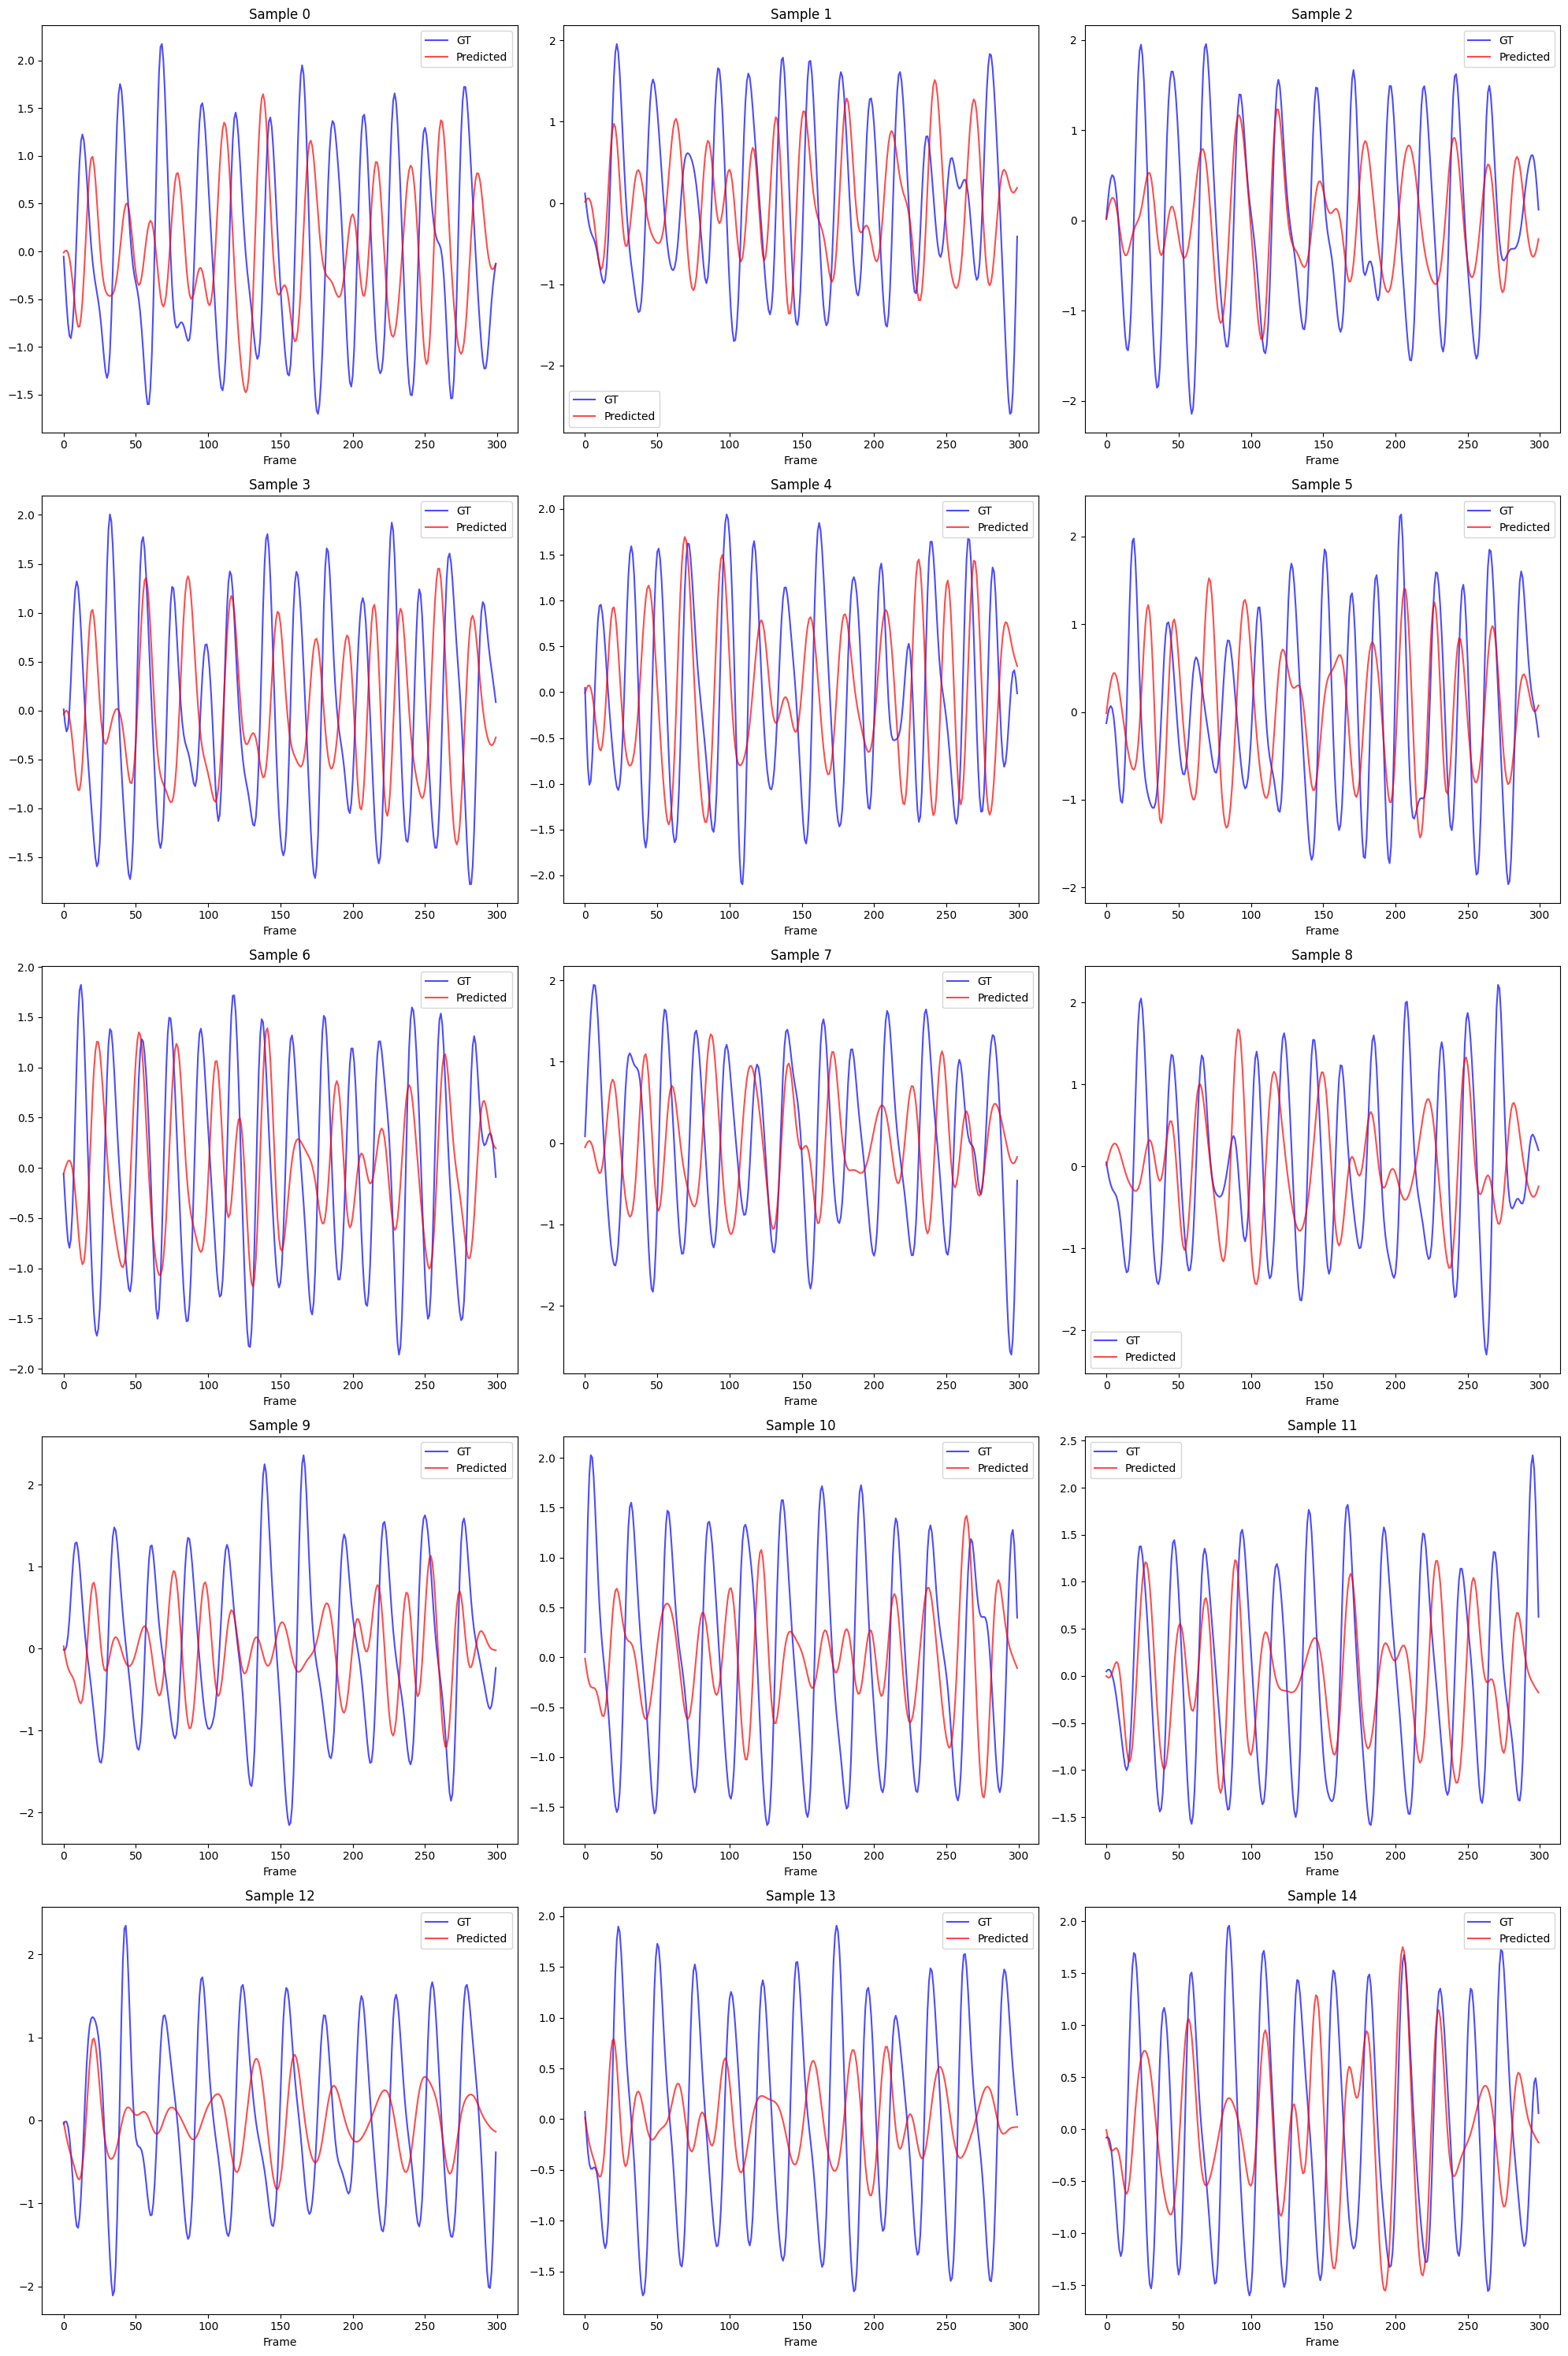

In [34]:
# ===== 설정 =====
device = torch.device("cuda" if torch.cuda.is_available() else "cpu")
pth_path = '/home/son/orientation-uv-rppg/data/codes/deeplearning/parameters_save/mr_nirp_0.0005_8_0.5407.pth'
data_dir = '/nasdata4/2yhy/rPPG_code/rPPG_datasets/raw_data/CNA_members/KM_preprocess_data/MR-nirp_driving_dl_data'
pic_save_dir ='/home/son/orientation-uv-rppg/data/pics/nirp_driving_result'
os.makedirs(pic_save_dir, exist_ok= True)
# ===== 모델 로드 =====
model = PhysNet_padding_Encoder_Decoder_MAX().to(device)
model.load_state_dict(torch.load(pth_path, map_location=device))
model.eval()
print("모델 로드 완료")


# ===== 데이터 로드 =====
all_files = sorted([os.path.join(data_dir, f) for f in os.listdir(data_dir) if f.endswith('.h5')])
valid_files = all_files[6:8]  # 학습 때 valid로 썼던 것

valid_dataset = rPPGDataset(valid_files)
valid_loader  = DataLoader(valid_dataset, batch_size=8, shuffle=False, num_workers=4)

# ===== 추론 =====
all_preds   = []
all_targets = []

with torch.no_grad():
    for inputs, targets in valid_loader:
        inputs  = inputs.to(device)
        print(inputs.shape)
        outputs, _, _, _ = model(inputs)

        all_preds.append(outputs.cpu().numpy())
        all_targets.append(targets.numpy())

all_preds   = np.concatenate(all_preds,   axis=0)  # (N, 300)
all_targets = np.concatenate(all_targets, axis=0)  # (N, 300)

for i in range(len(all_preds)) :
    all_preds[i] = butter_bandpass_filter(all_preds[i], 0.75, 2.5, 30)

print(f"추론 완료: preds {all_preds.shape}, targets {all_targets.shape}")

# ===== Plot =====
n_plot = 15  # 몇 개 샘플 볼지
fig, axes = plt.subplots(5, 3, figsize=(20, 30))
axes = axes.flatten()

for i in range(n_plot):
    axes[i].plot(all_targets[i], label='GT',        color='blue',  alpha=0.7)
    axes[i].plot(all_preds[i],   label='Predicted', color='red',   alpha=0.7)
    axes[i].set_title(f'Sample {i}')
    axes[i].legend()
    axes[i].set_xlabel('Frame')

plt.tight_layout()
plt.savefig(os.path.join(pic_save_dir, 'nirp_driving_valid_timedomain'), dpi= 100)
plt.show()


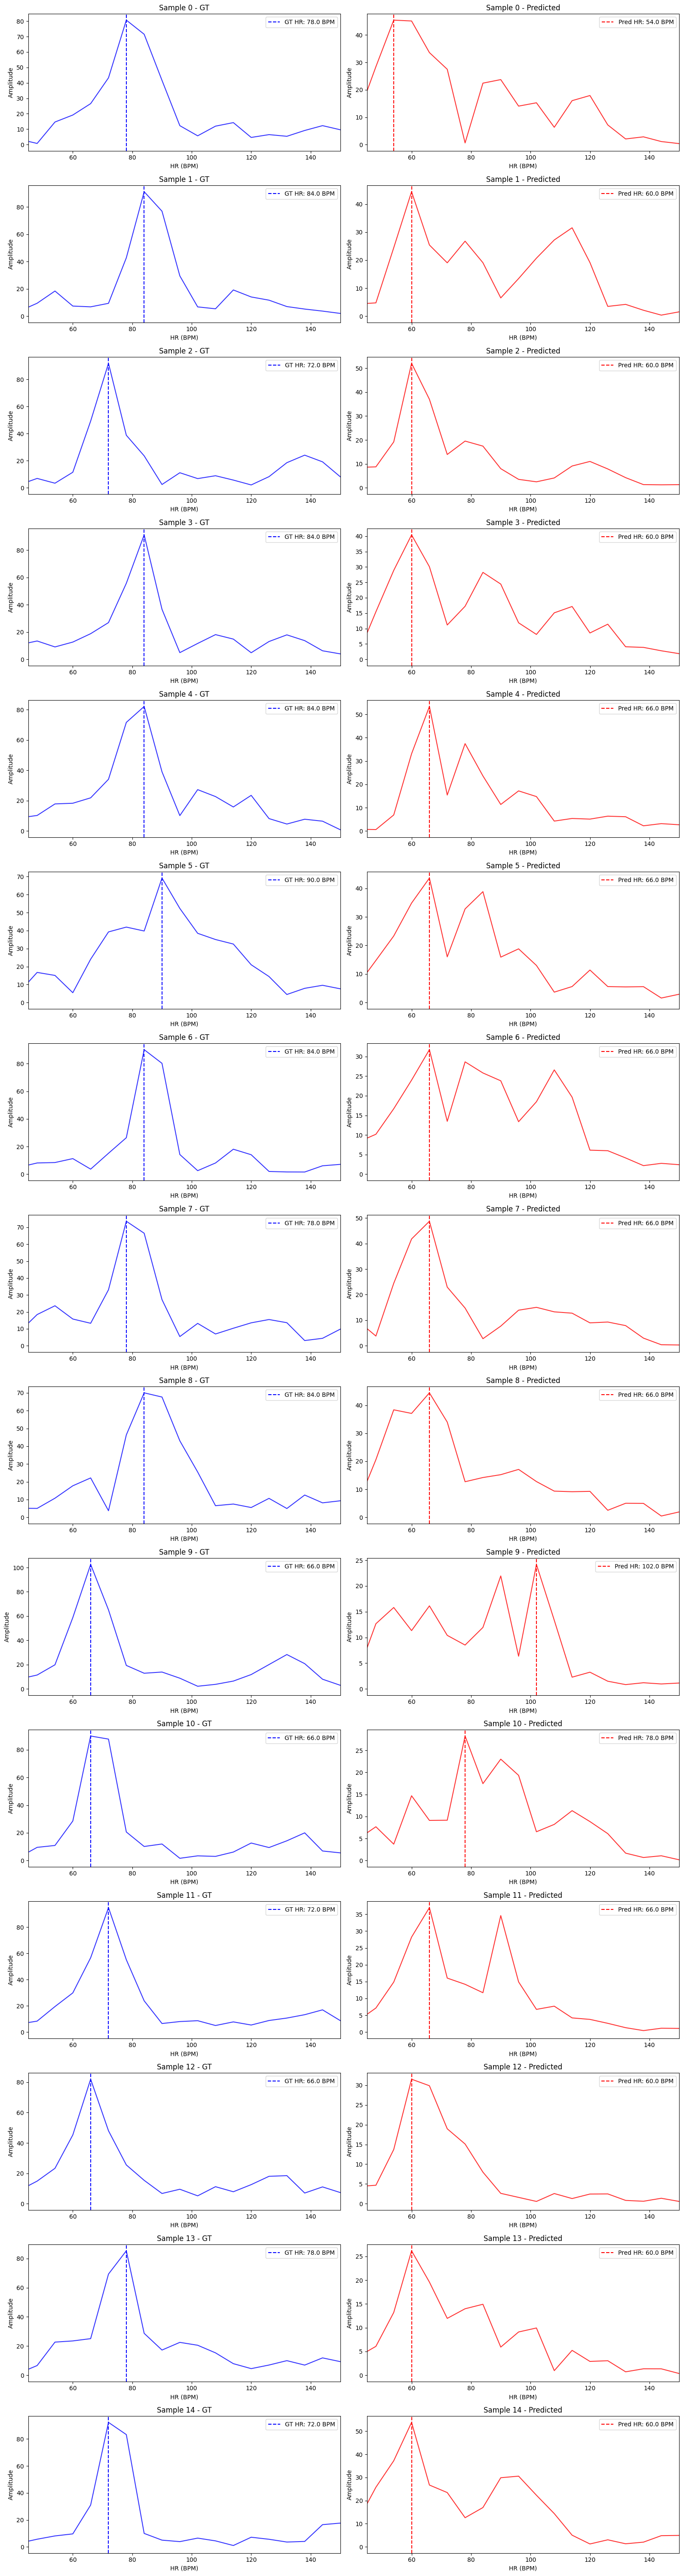

저장완료: fft_comparison.png


<Figure size 640x480 with 0 Axes>

In [35]:
from scipy.fft import fft

n_plot = 15
fig, axes = plt.subplots(n_plot, 2, figsize=(16, 4*n_plot))

for i in range(n_plot):
    pred_sig = all_preds[i]
    gt_sig   = all_targets[i]

    hr_pred, psd_pred, x_hr_pred = hr_fft(pred_sig, fs=30)
    hr_gt,   psd_gt,   x_hr_gt   = hr_fft(gt_sig,   fs=30)

    # GT PSD
    axes[i, 0].plot(x_hr_gt, psd_gt, color='blue', alpha=0.8)
    axes[i, 0].axvline(hr_gt,   color='blue',  linestyle='--', label=f'GT HR: {hr_gt:.1f} BPM')
    axes[i, 0].set_xlim(0.75*60, 2.5*60)
    axes[i, 0].set_title(f'Sample {i} - GT')
    axes[i, 0].set_xlabel('HR (BPM)')
    axes[i, 0].set_ylabel('Amplitude')
    axes[i, 0].legend()

    # Pred PSD
    axes[i, 1].plot(x_hr_pred, psd_pred, color='red', alpha=0.8)
    axes[i, 1].axvline(hr_pred, color='red',   linestyle='--', label=f'Pred HR: {hr_pred:.1f} BPM')
    axes[i, 1].set_xlim(0.75*60, 2.5*60)
    axes[i, 1].set_title(f'Sample {i} - Predicted')
    axes[i, 1].set_xlabel('HR (BPM)')
    axes[i, 1].set_ylabel('Amplitude')
    axes[i, 1].legend()

plt.tight_layout()

plt.show()
plt.savefig(os.path.join(pic_save_dir, 'nirp_uv_valid_frequencydomain'), dpi= 100)
print("저장완료: fft_comparison.png")